# OrgPilot AI — 분석 노트북

> ⚠ 이 노트북의 모든 데이터는 **합성(synthetic) 데이터**입니다. 가상 기업 *Aster Digital*을 가정해 `src/data_gen.py`로 생성했습니다.

모든 수치는 `src/` 모듈의 함수가 계산하며, 노트북은 호출·시각화만 합니다.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data_gen import SCHEMA, load
from src import kpi

plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 110,
})
IMG = ROOT / "docs" / "images"
IMG.mkdir(parents=True, exist_ok=True)

# 색 역할: 과부하(red) / 적정(gray) / 저활용(blue) — 1.0 기준 양극(diverging) 인코딩, 항상 텍스트 라벨 병기
STATUS_COLOR = {"과부하": "#e34948", "적정": "#a3a29b", "저활용": "#2a78d6"}
INK, MUTED = "#0b0b0b", "#52514e"

tables = {name: load(name) for name in SCHEMA}
{name: len(df) for name, df in tables.items()}

Out[1]: 
{'departments': 8,
 'employees': 300,
 'workload': 192,
 'skills': 1199,
 'staffing_plan': 192}


{'departments': 8,
 'employees': 300,
 'workload': 192,
 'skills': 1199,
 'staffing_plan': 192}

## Module A. 조직 생산성 진단

**KPI 정의** (`src/kpi.py`)

| KPI | 정의 |
|---|---|
| 필요 FTE | 업무건수 × 건당 표준시간 / 1인당 월 가용시간(140h) |
| 업무부하율 | 필요시간 / 가용시간 (가용시간 = 현원 × active 비율 × 140h) |
| 1인당 처리량 | 월 업무건수 / 가용인원 *(조직마다 업무 단위가 달라 조직 간 비교 불가, 조직 내 추이용)* |
| 초과근무 추정 | max(0, 필요시간 − 가용시간) / 가용인원 — 부족분을 초과근무로 메운다고 가정한 상한 |
| 상태 | 부하율 > 1.05 과부하, < 0.95 저활용, 그 외 적정 |

스냅샷은 최근 12개월(2025-10 ~ 2026-09)을 집계합니다.

In [2]:
k = kpi.department_kpis(tables).sort_values("load_ratio", ascending=False)
cols = {"name": "조직", "headcount": "현원", "active_headcount": "가용인원", "approved_to": "정원(TO)",
        "required_fte": "필요 FTE", "load_ratio": "부하율", "peak_load_ratio": "최대 월부하율",
        "overtime_per_person": "1인당 월 초과(h)", "overload_months": "과부하 개월수",
        "workload_yoy": "업무량 YoY", "status": "상태"}
(k[list(cols)].rename(columns=cols).style.hide(axis="index")
 .format({"필요 FTE": "{:.1f}", "부하율": "{:.2f}", "최대 월부하율": "{:.2f}",
          "1인당 월 초과(h)": "{:.1f}", "업무량 YoY": "{:+.0%}"}))

Out[2]: <pandas.io.formats.style.Styler at 0x2bd813bfd10>


조직,현원,가용인원,정원(TO),필요 FTE,부하율,최대 월부하율,1인당 월 초과(h),과부하 개월수,업무량 YoY,상태
AI서비스팀,24,23,26,29.3,1.37,1.53,52.3,12,+26%,과부하
클라우드인프라팀,38,37,38,43.0,1.21,1.29,29.4,12,+17%,과부하
정보보안팀,22,22,23,23.7,1.11,1.22,15.1,11,+7%,과부하
SI사업1팀,55,54,58,56.9,1.05,1.24,9.3,6,+4%,적정
PMO팀,30,30,30,29.8,0.99,1.11,4.3,5,+5%,적정
IT운영팀,50,47,52,46.5,0.97,1.07,1.4,4,-6%,적정
SI사업2팀,48,46,52,43.4,0.93,1.05,0.6,2,-2%,저활용
경영지원팀,33,33,35,28.6,0.85,0.97,0.0,0,-2%,저활용


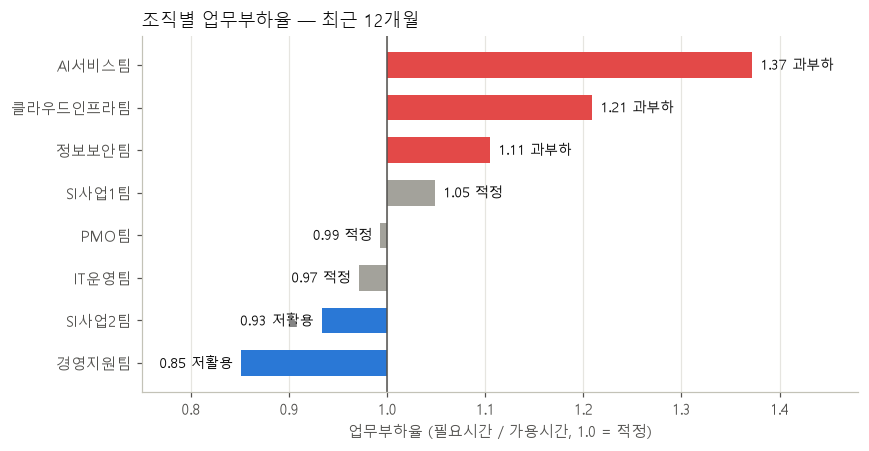

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
kk = k.sort_values("load_ratio")
bars = ax.barh(kk["name"], kk["load_ratio"] - 1, left=1, height=0.6,
               color=kk["status"].map(STATUS_COLOR))
ax.axvline(1, color=MUTED, lw=1)
for y, (v, s) in enumerate(zip(kk["load_ratio"], kk["status"])):
    off = 0.008 if v >= 1 else -0.008
    ax.text(v + off, y, f"{v:.2f} {s}", va="center", ha="left" if v >= 1 else "right", color=INK, fontsize=9)
ax.set_xlim(0.75, 1.48)
ax.set_xlabel("업무부하율 (필요시간 / 가용시간, 1.0 = 적정)")
ax.set_title("조직별 업무부하율 — 최근 12개월", loc="left", color=INK)
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(IMG / "a_load_ratio.png", bbox_inches="tight")

### 월별 업무부하율 추이
조직마다 하나의 패널(small multiples), 공통 y축. 점선 = 1.0(적정).

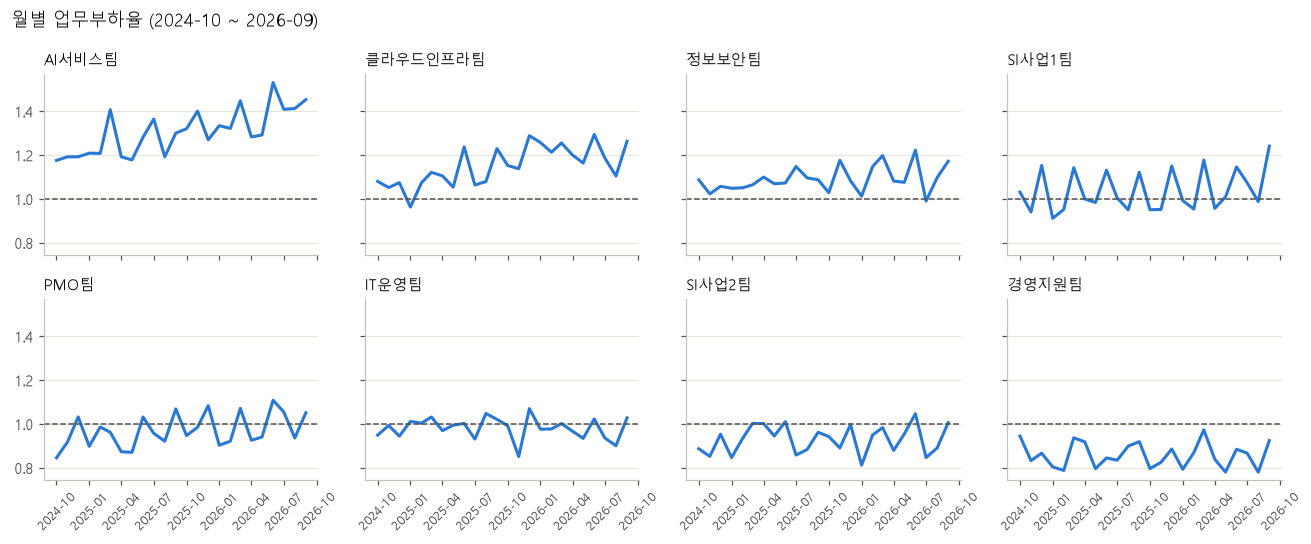

In [4]:
m = kpi.monthly_metrics(tables)
order = k["department_id"].tolist()
names = k.set_index("department_id")["name"]
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey=True)
for ax, d in zip(axes.flat, order):
    g = m[m["department_id"] == d]
    x = pd.PeriodIndex(g["period"], freq="M").to_timestamp()
    ax.plot(x, g["load_ratio"], color="#2a78d6", lw=2)
    ax.axhline(1, color=MUTED, lw=1, ls="--")
    ax.set_title(names[d], loc="left", fontsize=10, color=INK)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
fig.suptitle("월별 업무부하율 (2024-10 ~ 2026-09)", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(IMG / "a_monthly_load.png", bbox_inches="tight")

### 정원(TO)은 업무량을 반영하고 있는가
현재 정원은 "직전 연말 현원 + 부서 요청분"으로 정해졌습니다. 필요 FTE(최근 12개월 평균)와 나란히 놓으면 차이가 드러납니다.

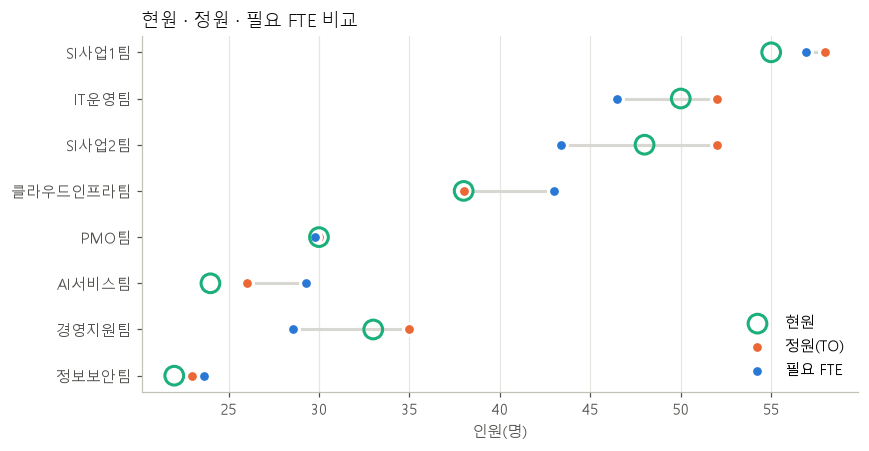

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
kk = k.sort_values("required_fte")
y = range(len(kk))
ax.hlines(y, kk[["approved_to", "required_fte"]].min(axis=1), kk[["approved_to", "required_fte"]].max(axis=1),
          color="#d8d7d1", lw=2)
# 현원은 속이 빈 큰 원: 정원·필요 FTE와 값이 겹쳐도 가려지지 않도록
ax.scatter(kk["headcount"], y, s=150, facecolor="none", edgecolor="#1baf7a", lw=2, label="현원", zorder=5)
ax.scatter(kk["approved_to"], y, s=60, color="#eb6834", label="정원(TO)", zorder=3, edgecolor="white", lw=2)
ax.scatter(kk["required_fte"], y, s=60, color="#2a78d6", label="필요 FTE", zorder=4, edgecolor="white", lw=2)
ax.set_yticks(list(y), kk["name"])
ax.set_xlabel("인원(명)")
ax.set_title("현원 · 정원 · 필요 FTE 비교", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(IMG / "a_to_vs_need.png", bbox_inches="tight")

In [6]:
gap = k.assign(정원_필요차=(k["approved_to"] - k["required_fte"]).round(1))[["name", "approved_to", "required_fte", "정원_필요차", "status"]]
gap.sort_values("정원_필요차").style.hide(axis="index").format({"required_fte": "{:.1f}"})

Out[6]: <pandas.io.formats.style.Styler at 0x2bd816996a0>


name,approved_to,required_fte,정원_필요차,status
클라우드인프라팀,38,43.0,-5.000000,과부하
AI서비스팀,26,29.3,-3.300000,과부하
정보보안팀,23,23.7,-0.700000,과부하
PMO팀,30,29.8,0.200000,적정
SI사업1팀,58,56.9,1.100000,적정
IT운영팀,52,46.5,5.500000,적정
경영지원팀,35,28.6,6.400000,저활용
SI사업2팀,52,43.4,8.600000,저활용


**해석 (Module A)**
- 과부하 조직은 업무량이 전년 대비 크게 늘어난 조직과 겹칩니다. 연초 1회 "현원 + 요청분"으로 정해지는 정원은 연중 성장을 따라가지 못합니다.
- 저활용 조직은 업무량이 줄었지만 정원은 과거 현원 기준으로 유지되어, 필요 인원보다 정원이 큽니다.
- 부하율이 연평균으로 적정이어도 분기말 피크에는 1.0을 넘는 조직이 있습니다(최대 월부하율·과부하 개월수 참고). 정원은 평균 기준으로, 피크는 일시 지원·초과근무로 대응할지 판단이 필요합니다.
- 다음 단계(Module B): 과거 평균이 아니라 **향후 업무량 예측**으로 필요 FTE를 산정합니다.